# The quasi-Riemann Hypothesis (2026)

*A companion notebook to* **Prime Numbers and the Riemann Hypothesis** *by Barry Mazur and William Stein (Cambridge University Press, 2016), Part IV, "Back to Riemann", written after the book: in 2026 the quasi-Riemann Hypothesis became a theorem.*

The book ends with Riemann's way of building the staircase of primes from the spectrum:

> Bernhard Riemann used the spectrum of the prime numbers to provide an exact analytic formula that analyzes and/or synthesizes the staircase of primes. This formula is motivated by Fourier's analysis of functions as constituted out of cosines.

Each zero $\rho$ of $\zeta(s)$ contributes one wave to that formula, and its size is $x^{\operatorname{Re}\rho}$. So *where* the zeros are, how far to the right they can sit, decides how well we can count primes. In this notebook you will:

1. see the critical strip, the Riemann Hypothesis, and the quasi-Riemann Hypothesis as statements about where zeros may lie;
2. compare the zero-free region known before 2026 (which gets thinner and thinner) with the new one (which does not);
3. put a hypothetical zero off the critical line into Riemann's formula and watch what it would do to the primes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
GAMMA = np.array([float(line) for line in open('zeta_zeros_1000.txt') if not line.startswith('#')])

## 1. Where can the zeros be?

The nontrivial zeros of $\zeta(s)$ lie in the **critical strip** $0 < \operatorname{Re}(s) < 1$ (Hadamard and de la Vallée Poussin, 1896), symmetrically about the **critical line** $\operatorname{Re}(s) = \tfrac12$. Every zero computed so far, more than ten trillion of them, lies exactly on the line.

* **The Riemann Hypothesis:** every nontrivial zero has real part $\tfrac12$.
* **The quasi-Riemann Hypothesis**, $\mathrm{QRH}(a)$ for a fixed $a > 0$: every nontrivial zero satisfies $a \le \operatorname{Re}(\rho) \le 1 - a$.

$\mathrm{QRH}(a)$ asks for far less than RH, only a strip of fixed width that keeps the zeros away from the edges, but no such strip was known for over a century. In October 2026 OpenAI announced AI-generated proofs of $\mathrm{QRH}(1/12)$ (49 pages) and of $\mathrm{QRH}(1/8)$ (199 pages, formally verified in Lean). Number theorists who have studied the shorter proof largely agree that it is correct; at the time of writing it had not been through journal peer review (see the sources at the end).

The picture shows the strip, the first zeros (all on the line), and the regions $\mathrm{QRH}(1/12)$ now rules out.

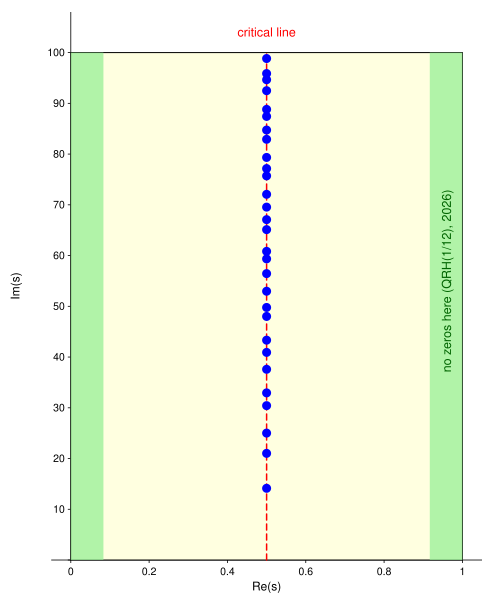

In [2]:
@interact
def critical_strip(height=selector([50, 100, 200], default=100, label='t up to')):
    g = polygon([(0, 0), (1, 0), (1, height), (0, height)], color='lightyellow', edgecolor='black')
    g += polygon([(11/12, 0), (1, 0), (1, height), (11/12, height)], color='lightgreen', alpha=0.7)
    g += polygon([(0, 0), (1/12, 0), (1/12, height), (0, height)], color='lightgreen', alpha=0.7)
    g += line([(1/2, 0), (1/2, height)], color='red', linestyle='--')
    g += points([(1/2, t0) for t0 in GAMMA[GAMMA <= height]], color='blue', size=25)
    g += text('no zeros here (QRH(1/12), 2026)', (0.96, height * 0.55), rotation=90, fontsize=9, color='darkgreen')
    g += text('critical line', (0.5, height * 1.04), fontsize=9, color='red')
    show(g, axes_labels=['Re(s)', 'Im(s)'], xmin=-0.05, xmax=1.05, ymax=height * 1.08, figsize=[5, 6], aspect_ratio='automatic')

## 2. Thinner and thinner, or a fixed width

Before 2026, every proved zero-free region near $\operatorname{Re}(s) = 1$ had the shape
$$\operatorname{Re}(s) > 1 - \frac{c}{\log t}$$
(de la Vallée Poussin's), or the slightly better $1 - c/(\log t)^{2/3}(\log\log t)^{1/3}$ of Vinogradov and Korobov. Both get thinner as $t$ grows, so neither ruled out zeros creeping towards the line $\operatorname{Re}(s) = 1$ high up in the strip. That is why the error term in the Prime Number Theorem was only known to be smaller than $x$ by a factor slower than any power of $x$. The quasi-Riemann Hypothesis gives a width that never shrinks. The constant $c$ below is illustrative; only the shapes matter.

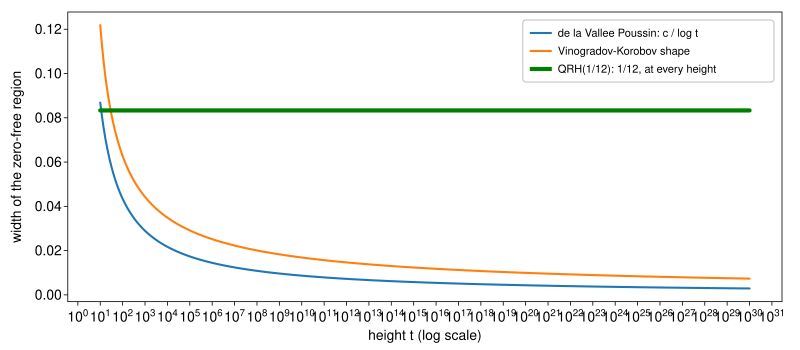

In [3]:
@interact
def widths(c=slider(0.05, 0.5, 0.05, 0.2, label='constant c (illustrative)')):
    t = np.logspace(1, 30, 400)
    plt.figure(figsize=(8, 3.5))
    plt.semilogx(t, c / np.log(t), label='de la Vallee Poussin: c / log t')
    plt.semilogx(t, c / (np.log(t)**(2/3) * np.log(np.log(t))**(1/3)), label='Vinogradov-Korobov shape')
    plt.semilogx(t, np.full_like(t, 1 / 12), 'g', linewidth=3, label='QRH(1/12): 1/12, at every height')
    plt.xlabel('height t (log scale)')
    plt.ylabel('width of the zero-free region')
    plt.legend()
    plt.show()

## 3. A zero off the line

Riemann's formula, in von Mangoldt's form, says
$$\psi(x) - x \;=\; -\sum_{\rho}\frac{x^{\rho}}{\rho} + (\text{small}),$$
where $\psi(x) = \sum_{p^n \le x}\log p$ (see the notebook *The Riemann spectrum and the staircase of primes*). With every zero on the line, each term has size $\sqrt{x}/|\rho|$, so $(\psi(x) - x)/\sqrt{x}$ stays small: under the Riemann Hypothesis it grows at most like $(\log x)^2$ (Littlewood showed it does grow without bound, but extremely slowly), as the blue curve (the actual primes up to $10^6$) suggests.

Now imagine one more pair of zeros, $\beta \pm 100i$, off the line. Its wave $-2\,\mathrm{Re}(x^{\rho}/\rho)$ grows like $x^{\beta}$, so divided by $\sqrt{x}$ it grows like $x^{\beta - 1/2}$: for $\beta$ near $1$ it swamps everything, and the primes would be far less regular than they are. Move $\beta$ to see the effect, and where the 2026 theorem now draws the line ($\beta \le \tfrac{11}{12}$).

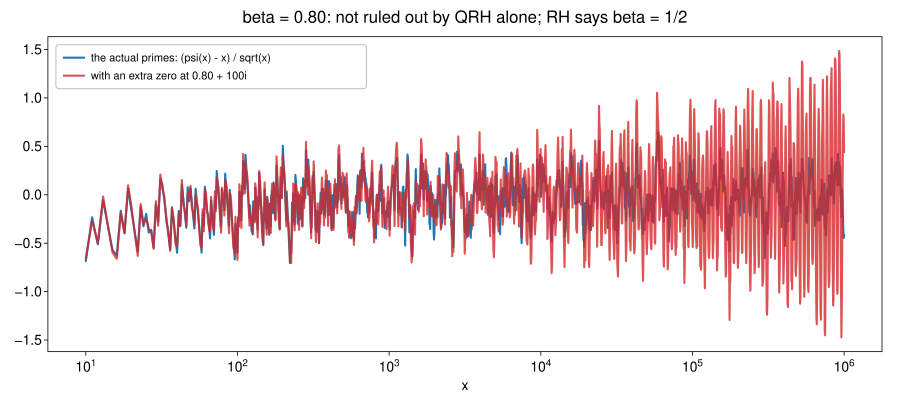

In [4]:
B = 10^6
psi = np.zeros(B + 1)
for p in prime_range(B + 1):
    q = p
    while q <= B:
        psi[q] += float(log(p))
        q *= p
psi = np.cumsum(psi)
xs = np.unique(np.logspace(1, 6, 2000).astype(int))
actual = (psi[xs] - xs) / np.sqrt(xs)

@interact
def zero_off_the_line(beta=slider(0.5, 0.99, 0.01, 0.8, label='real part beta of the extra zero')):
    rho = beta + 100j
    wave = -2 * (np.exp(rho * np.log(xs)) / rho).real / np.sqrt(xs)
    plt.figure(figsize=(9, 4))
    plt.semilogx(xs, actual, color='tab:blue', label='the actual primes: (psi(x) - x) / sqrt(x)')
    plt.semilogx(xs, actual + wave, color='tab:red', alpha=0.8, label='with an extra zero at %.2f + 100i' % beta)
    plt.title('beta = %.2f: %s' % (beta, 'ruled out by QRH(1/12)' if beta > 11/12 else 'not ruled out by QRH alone; RH says beta = 1/2'))
    plt.xlabel('x')
    plt.legend(loc='upper left')
    plt.show()

## 4. What changes for the primes

The error in the Prime Number Theorem is controlled by the zero furthest to the right. Writing $E(x) = \operatorname{Li}(x) - \pi(x)$:

| what is known | the error $E(x)$ |
|---|---|
| before 2026, unconditionally | smaller than $x$ by a factor $\exp\!\big(c(\log x)^{3/5}(\log\log x)^{-1/5}\big)$, slower than any power of $x$ |
| $\mathrm{QRH}(1/12)$, 2026 | $O(x^{\theta})$ for every $\theta > \tfrac{11}{12}$ |
| $\mathrm{QRH}(1/8)$, if the longer proof holds | $O(x^{\theta})$ for every $\theta > \tfrac78$ |
| the Riemann Hypothesis | $O(\sqrt{x}\,\log x)$: square-root error, the best possible exponent |

For the first time, the error is smaller than a fixed power $x^{\theta}$ with $\theta < 1$: a "power saving". As Maksym Radziwiłł put it, *"in a sense, the vast majority of consequences of RH already follow from quasi-RH."* The Riemann Hypothesis itself, that the strip has width $0$, remains open.

## Sources

* *[AI Proved the Quasi-Riemann Hypothesis. What Happens Now?](https://www.quantamagazine.org/ai-proved-the-quasi-riemann-hypothesis-what-happens-now-20261019/)*, Quanta Magazine, 19 October 2026.
* John Baez, *[The Quasi-Riemann Hypothesis](https://johncarlosbaez.wordpress.com/2026/10/21/the-quasi-riemann-hypothesis/)*, Azimuth, 21 October 2026.
* The notebook *How good is $\operatorname{Li}(x)$?*, for the error term itself and its data.

## Things to try

1. In section 3, change the height of the extra zero from $100$ to $1000$. Why does the effect take longer to show?
2. Put the extra zero at $\beta = \tfrac{11}{12}$ exactly. Up to which $x$ could such a zero hide inside the natural fluctuations of the blue curve?
3. Read Baez's post on what $\mathrm{QRH}(a)$ for other $L$-functions (Dirichlet, Dedekind) would say about primes in arithmetic progressions and in number fields.

---
*Written for the companion notebooks to* Prime Numbers and the Riemann Hypothesis *(Barry Mazur and William Stein, Cambridge University Press, 2016); quotations are from the book. The zeros in `zeta_zeros_1000.txt` were computed with mpmath. MIT license. Runs in the browser with [Sagebrush](https://sagebrush.space).*